In [3]:
# Manuscript descriptive analysis
# Paper_Dataset_PON

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

FIGURES_DIR = Path("figures")
TABLES_DIR = Path("tables")

FIGURES_DIR.mkdir(exist_ok=True)
TABLES_DIR.mkdir(exist_ok=True)

print("Manuscript analysis environment ready.")

Manuscript analysis environment ready.


In [4]:
# Load the final publication dataset

DATA_PATH = Path("Dataset_Publication_v1.0.xlsx")  # change filename if needed

df = pd.read_excel(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (6065, 39)


,optical_tx_power_dbm,wavelength_nm,modulator_type,modulator_attenuation_db,vbias_v,experiment_campaign,bits_tx,transmission_rate_bps,rf_voltage_v,rf_power_dbm,...,jitter_ps,jitter_source,ml_task_evm,ml_task_q,ml_task_jitter,qot_class,qot_basis,group_key,group_id,ml_split
0,16.0,1551.0,8019028IM,4.33,1.6,LTE_QPSK,800000000,800000000,0.070711,-10.0,...,NaN,Not_available,Use,No_use,No_use,Degraded,EVM_measured,LTE_QPSK|16|1551|8019028IM|800000000|25|35,G0001,Train
1,8.0,1550.0,8019028IM,4.33,1.7,LTE_QPSK,800000000,800000000,0.070711,-10.0,...,NaN,Not_available,Use,No_use,No_use,Degraded,EVM_measured,LTE_QPSK|8|1550|8019028IM|800000000|25|27,G0002,Test
2,8.0,1550.0,8019028IM,4.33,1.6,LTE_QPSK,800000000,800000000,0.070711,-10.0,...,NaN,Not_available,Use,No_use,No_use,Degraded,EVM_measured,LTE_QPSK|8|1550|8019028IM|800000000|25|27,G0002,Test
3,12.0,1551.0,8019028IM,4.33,1.4,LTE_QPSK,800000000,800000000,0.070711,-10.0,...,NaN,Not_available,Use,No_use,No_use,Degraded,EVM_measured,LTE_QPSK|12|1551|8019028IM|800000000|25|30,G0004,Test
4,15.0,1551.0,8019028IM,4.33,1.6,LTE_QPSK,800000000,800000000,0.070711,-10.0,...,NaN,Not_available,Use,No_use,No_use,Degraded,EVM_measured,LTE_QPSK|15|1551|8019028IM|800000000|25|33,G0005,Train


In [5]:
# Step 1 — Inspect loaded dataset

print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Shape: (6065, 39)

Columns:
['optical_tx_power_dbm', 'wavelength_nm', 'modulator_type', 'modulator_attenuation_db', 'vbias_v', 'experiment_campaign', 'bits_tx', 'transmission_rate_bps', 'rf_voltage_v', 'rf_power_dbm', 'rf_amplifier_tx_db', 'smf_length_km', 'smf_attenuation_db', 'dispersion_ps_nm_km', 'voa_attenuation_db', 'edfa_current_ma', 'soa_current_ma', 'prx_dbm', 'photodiode', 'max_allowed_optical_power_dbm', 'optical_receiver_responsivity_a_w', 'detector_bw_hz', 'rf_amplifier_rx_db', 'ber', 'ber_source', 'evm_percent', 'evm_source', 'q_factor', 'q_factor_source', 'jitter_ps', 'jitter_source', 'ml_task_evm', 'ml_task_q', 'ml_task_jitter', 'qot_class', 'qot_basis', 'group_key', 'group_id', 'ml_split']


,optical_tx_power_dbm,wavelength_nm,modulator_type,modulator_attenuation_db,vbias_v,experiment_campaign,bits_tx,transmission_rate_bps,rf_voltage_v,rf_power_dbm,...,jitter_ps,jitter_source,ml_task_evm,ml_task_q,ml_task_jitter,qot_class,qot_basis,group_key,group_id,ml_split
0,16.0,1551.0,8019028IM,4.33,1.6,LTE_QPSK,800000000,800000000,0.070711,-10.0,...,NaN,Not_available,Use,No_use,No_use,Degraded,EVM_measured,LTE_QPSK|16|1551|8019028IM|800000000|25|35,G0001,Train
1,8.0,1550.0,8019028IM,4.33,1.7,LTE_QPSK,800000000,800000000,0.070711,-10.0,...,NaN,Not_available,Use,No_use,No_use,Degraded,EVM_measured,LTE_QPSK|8|1550|8019028IM|800000000|25|27,G0002,Test
2,8.0,1550.0,8019028IM,4.33,1.6,LTE_QPSK,800000000,800000000,0.070711,-10.0,...,NaN,Not_available,Use,No_use,No_use,Degraded,EVM_measured,LTE_QPSK|8|1550|8019028IM|800000000|25|27,G0002,Test
3,12.0,1551.0,8019028IM,4.33,1.4,LTE_QPSK,800000000,800000000,0.070711,-10.0,...,NaN,Not_available,Use,No_use,No_use,Degraded,EVM_measured,LTE_QPSK|12|1551|8019028IM|800000000|25|30,G0004,Test
4,15.0,1551.0,8019028IM,4.33,1.6,LTE_QPSK,800000000,800000000,0.070711,-10.0,...,NaN,Not_available,Use,No_use,No_use,Degraded,EVM_measured,LTE_QPSK|15|1551|8019028IM|800000000|25|33,G0005,Train


In [6]:
# Step 2 — QoT class distribution by experimental campaign

class_distribution = pd.crosstab(
    df["experiment_campaign"],
    df["qot_class"],
    margins=True
)

display(class_distribution)

qot_class,Acceptable,Degraded,Excellent,Not_available,All
experiment_campaign,,,,,
LTE_QPSK,155,1224,151,2,1532
PRBS_NRZ,639,2022,1870,2,4533
All,794,3246,2021,4,6065


In [7]:
# Step 3 — QoT class percentages by campaign

class_counts = pd.crosstab(
    df["experiment_campaign"],
    df["qot_class"]
)

class_percentages = (
    class_counts
    .div(class_counts.sum(axis=1), axis=0)
    * 100
)

class_percentages = class_percentages.round(2)

display(class_percentages)

qot_class,Acceptable,Degraded,Excellent,Not_available
experiment_campaign,,,,
LTE_QPSK,10.12,79.90,9.86,0.13
PRBS_NRZ,14.10,44.61,41.25,0.04


In [8]:
# Step 4 — Prepare QoT distribution table for manuscript figure

plot_qot_distribution = (
    class_percentages[
        [
            "Excellent",
            "Acceptable",
            "Degraded"
        ]
    ]
    .copy()
    .reset_index()
)

plot_qot_distribution["Campaign"] = (
    plot_qot_distribution["experiment_campaign"]
    .replace({
        "PRBS_NRZ": "PRBS-NRZ",
        "LTE_QPSK": "LTE-QPSK"
    })
)

plot_qot_distribution = (
    plot_qot_distribution[
        [
            "Campaign",
            "Excellent",
            "Acceptable",
            "Degraded"
        ]
    ]
)

display(plot_qot_distribution)

qot_class,Campaign,Excellent,Acceptable,Degraded
0,LTE-QPSK,9.86,10.12,79.90
1,PRBS-NRZ,41.25,14.10,44.61


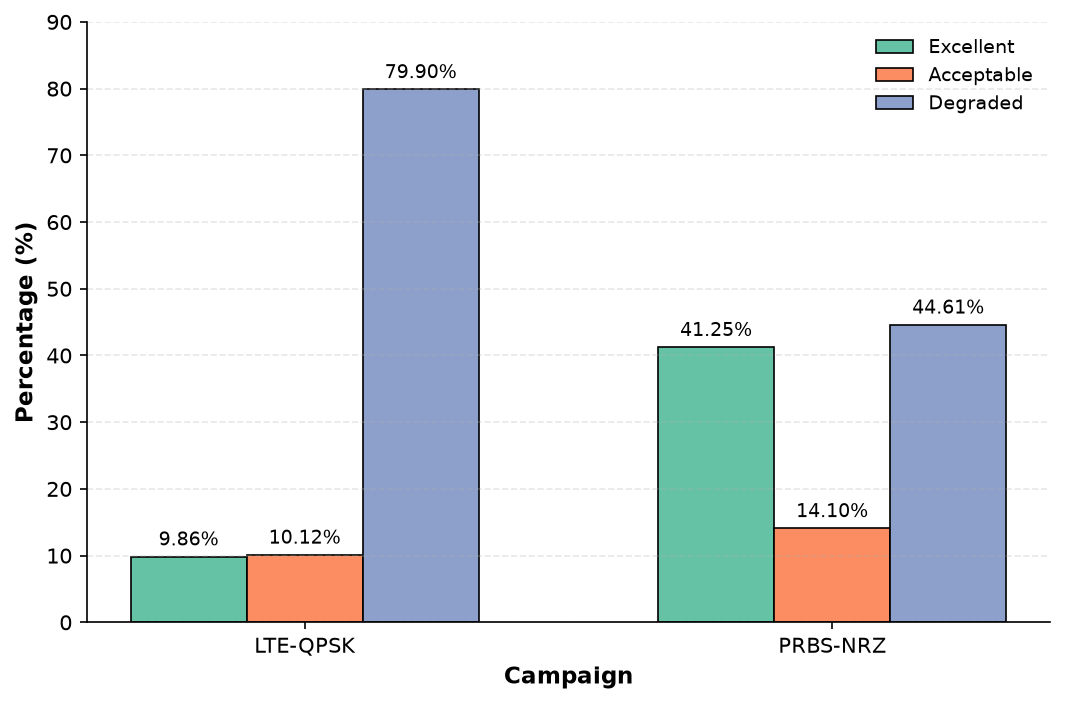

Saved: figures/results\qot_class_distribution_by_campaign.pdf


In [9]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# Datos
# =========================
plot_df = pd.DataFrame({
    "Campaign": ["LTE-QPSK", "PRBS-NRZ"],
    "Excellent": [9.86, 41.25],
    "Acceptable": [10.12, 14.10],
    "Degraded": [79.90, 44.61]
})

# =========================
# Carpeta de salida
# =========================
output_dir = "figures/results"
os.makedirs(output_dir, exist_ok=True)

save_path = os.path.join(
    output_dir,
    "qot_class_distribution_by_campaign.pdf"
)

# =========================
# Estilo IEEE + Set2
# =========================
plt.style.use("default")

set2_colors = plt.get_cmap("Set2").colors
colors = [set2_colors[0], set2_colors[1], set2_colors[2]]

classes = ["Excellent", "Acceptable", "Degraded"]
x = np.arange(len(plot_df["Campaign"]))
width = 0.22

fig, ax = plt.subplots(figsize=(7.2, 4.8), dpi=150)

for i, cls in enumerate(classes):
    values = plot_df[cls].values

    bars = ax.bar(
        x + (i - 1) * width,
        values,
        width=width,
        label=cls,
        color=colors[i],
        edgecolor="black",
        linewidth=0.8
    )

    # =========================
    # Etiquetas en porcentaje
    # =========================
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 1.0,                 # un poco arriba de la barra
            f"{height:.2f}%",
            ha="center",
            va="bottom",
            fontsize=9
        )

# =========================
# Formato de ejes
# =========================
ax.set_xlabel("Campaign", fontweight="bold", fontsize=11)
ax.set_ylabel("Percentage (%)", fontweight="bold", fontsize=11)

ax.set_xticks(x)
ax.set_xticklabels(plot_df["Campaign"], fontsize=10)
ax.tick_params(axis="y", labelsize=10)

ax.set_ylim(0, 90)   # deja espacio para las etiquetas
ax.grid(axis="y", linestyle="--", alpha=0.3)

# Bordes
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(0.8)
ax.spines["bottom"].set_linewidth(0.8)

# Leyenda
ax.legend(frameon=False, fontsize=9)

plt.tight_layout()
plt.savefig(save_path, format="pdf", bbox_inches="tight")
plt.show()

print("Saved:", save_path)

In [10]:
# Step 6 — Statistical characterization of key experimental variables

key_variables = [
    "optical_tx_power_dbm",
    "wavelength_nm",
    "vbias_v",
    "transmission_rate_bps",
    "rf_power_dbm",
    "smf_length_km",
    "smf_attenuation_db",
    "dispersion_ps_nm_km",
    "voa_attenuation_db",
    "edfa_current_ma",
    "soa_current_ma",
    "prx_dbm"
]

statistical_summary = []

for campaign in ["LTE_QPSK", "PRBS_NRZ"]:

    subset = df[
        df["experiment_campaign"] == campaign
    ]

    for variable in key_variables:

        values = subset[variable].dropna()

        statistical_summary.append({
            "Campaign": campaign,
            "Variable": variable,
            "N": len(values),
            "Missing": subset[variable].isna().sum(),
            "Median": values.median(),
            "Q1": values.quantile(0.25),
            "Q3": values.quantile(0.75),
            "IQR": (
                values.quantile(0.75)
                - values.quantile(0.25)
            ),
            "Min": values.min(),
            "Max": values.max()
        })

statistical_summary = pd.DataFrame(
    statistical_summary
)

display(
    statistical_summary.round(4)
)

,Campaign,Variable,N,Missing,Median,Q1,Q3,IQR,Min,Max
0,LTE_QPSK,optical_tx_power_dbm,1532,0,8.000000e+00,7.000000e+00,8.000000e+00,1.000000e+00,6.000000e+00,1.600000e+01
1,LTE_QPSK,wavelength_nm,1532,0,1.550000e+03,1.550000e+03,1.551000e+03,1.000000e+00,1.550000e+03,1.553000e+03
2,LTE_QPSK,vbias_v,1532,0,2.400000e+00,8.000000e-01,3.100000e+00,2.300000e+00,0.000000e+00,5.000000e+00
3,LTE_QPSK,transmission_rate_bps,1532,0,8.000000e+08,8.000000e+08,8.000000e+08,0.000000e+00,8.000000e+08,8.000000e+08
4,LTE_QPSK,rf_power_dbm,1532,0,-1.000000e+01,-1.300000e+01,-1.000000e+01,3.000000e+00,-4.500000e+01,1.900000e+01
5,LTE_QPSK,smf_length_km,1532,0,2.500000e+01,2.500000e+01,2.500000e+01,0.000000e+00,2.500000e+01,2.500000e+01
6,LTE_QPSK,smf_attenuation_db,1532,0,4.630000e+00,4.630000e+00,4.670000e+00,4.000000e-02,4.460000e+00,5.360000e+00
7,LTE_QPSK,dispersion_ps_nm_km,1532,0,1.800000e+01,1.800000e+01,1.800000e+01,0.000000e+00,1.800000e+01,1.800000e+01
8,LTE_QPSK,voa_attenuation_db,1532,0,1.800000e+01,1.000000e+01,2.700000e+01,1.700000e+01,7.000000e+00,4.100000e+01
9,LTE_QPSK,edfa_current_ma,1513,19,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00


In [11]:
# Step 7 — Compact statistical summary for manuscript

selected_variables = [
    "optical_tx_power_dbm",
    "wavelength_nm",
    "vbias_v",
    "transmission_rate_bps",
    "smf_length_km",
    "voa_attenuation_db",
    "soa_current_ma",
    "prx_dbm"
]

variable_labels = {
    "optical_tx_power_dbm": "Tx optical power (dBm)",
    "wavelength_nm": "Wavelength (nm)",
    "vbias_v": "Vbias (V)",
    "transmission_rate_bps": "Transmission rate (Gb/s)",
    "smf_length_km": "SMF length (km)",
    "voa_attenuation_db": "VOA attenuation (dB)",
    "soa_current_ma": "SOA current (mA)",
    "prx_dbm": "PRx (dBm)"
}

compact_rows = []

for campaign in ["LTE_QPSK", "PRBS_NRZ"]:

    subset = df[
        df["experiment_campaign"] == campaign
    ]

    for variable in selected_variables:

        values = subset[variable].dropna().copy()

        # Convert transmission rate to Gb/s
        if variable == "transmission_rate_bps":
            values = values / 1e9

        median = values.median()
        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        minimum = values.min()
        maximum = values.max()

        compact_rows.append({
            "Campaign": campaign.replace("_", "-"),
            "Variable": variable_labels[variable],
            "Median": median,
            "Q1": q1,
            "Q3": q3,
            "Min": minimum,
            "Max": maximum,
            "Missing": subset[variable].isna().sum()
        })

statistical_manuscript = pd.DataFrame(compact_rows)

display(
    statistical_manuscript.round(2)
)

,Campaign,Variable,Median,Q1,Q3,Min,Max,Missing
0,LTE-QPSK,Tx optical power (dBm),8.00,7.00,8.00,6.00,16.00,0
1,LTE-QPSK,Wavelength (nm),1550.00,1550.00,1551.00,1550.00,1553.00,0
2,LTE-QPSK,Vbias (V),2.40,0.80,3.10,0.00,5.00,0
3,LTE-QPSK,Transmission rate (Gb/s),0.80,0.80,0.80,0.80,0.80,0
4,LTE-QPSK,SMF length (km),25.00,25.00,25.00,25.00,25.00,0
5,LTE-QPSK,VOA attenuation (dB),18.00,10.00,27.00,7.00,41.00,0
6,LTE-QPSK,SOA current (mA),200.50,181.25,207.90,0.00,370.00,0
7,LTE-QPSK,PRx (dBm),-26.80,-32.61,-18.45,-56.15,-5.82,1
8,PRBS-NRZ,Tx optical power (dBm),8.00,7.00,8.00,5.30,9.00,0
9,PRBS-NRZ,Wavelength (nm),1553.33,1550.00,1555.75,1550.00,1557.00,0


In [12]:
# Step 8 — Compact statistical characterization table for manuscript

from pathlib import Path

TABLES_DIR = Path("tables/results_section")
TABLES_DIR.mkdir(parents=True, exist_ok=True)

statistical_manuscript_compact = statistical_manuscript.copy()

# Create compact summary:
# Median [Q1–Q3]; Range (Min–Max)
statistical_manuscript_compact["Summary"] = (
    statistical_manuscript_compact.apply(
        lambda row:
        f"{row['Median']:.2f} "
        f"[{row['Q1']:.2f}–{row['Q3']:.2f}]; "
        f"{row['Min']:.2f}–{row['Max']:.2f}",
        axis=1
    )
)

# Add missing count only when present
statistical_manuscript_compact["Summary"] = (
    statistical_manuscript_compact.apply(
        lambda row:
        row["Summary"]
        if row["Missing"] == 0
        else f"{row['Summary']} (missing={int(row['Missing'])})",
        axis=1
    )
)

# Pivot to one row per variable
statistical_table_final = (
    statistical_manuscript_compact
    .pivot(
        index="Variable",
        columns="Campaign",
        values="Summary"
    )
    .reset_index()
)

# Keep desired campaign order
statistical_table_final = statistical_table_final[
    [
        "Variable",
        "PRBS-NRZ",
        "LTE-QPSK"
    ]
]

display(statistical_table_final)

# Save
output_file = (
    TABLES_DIR /
    "table_statistical_characterization.csv"
)

statistical_table_final.to_csv(
    output_file,
    index=False
)

print("Saved:", output_file)

Campaign,Variable,PRBS-NRZ,LTE-QPSK
0,PRx (dBm),-17.74 [-20.61–-14.82]; -39.50–-4.95 (missing=44),-26.80 [-32.61–-18.45]; -56.15–-5.82 (missing=1)
1,SMF length (km),25.00 [20.00–25.00]; 20.00–50.00,25.00 [25.00–25.00]; 25.00–25.00
2,SOA current (mA),191.60 [188.00–202.00]; 0.00–268.00 (missing=5),200.50 [181.25–207.90]; 0.00–370.00
3,Transmission rate (Gb/s),2.48 [1.25–6.00]; 0.50–10.30,0.80 [0.80–0.80]; 0.80–0.80
4,Tx optical power (dBm),8.00 [7.00–8.00]; 5.30–9.00,8.00 [7.00–8.00]; 6.00–16.00
5,VOA attenuation (dB),10.00 [10.00–13.00]; 0.00–35.00,18.00 [10.00–27.00]; 7.00–41.00
6,Vbias (V),2.60 [1.60–3.70]; 0.00–6.30,2.40 [0.80–3.10]; 0.00–5.00
7,Wavelength (nm),1553.33 [1550.00–1555.75]; 1550.00–1557.00,1550.00 [1550.00–1551.00]; 1550.00–1553.00


Saved: tables\results_section\table_statistical_characterization.csv


In [13]:
# Step 9 — Experimental-variable distributions by QoT class

analysis_variables = [
    "optical_tx_power_dbm",
    "wavelength_nm",
    "vbias_v",
    "transmission_rate_bps",
    "smf_length_km",
    "voa_attenuation_db",
    "soa_current_ma",
    "prx_dbm"
]

qot_order = [
    "Excellent",
    "Acceptable",
    "Degraded"
]

# Keep only records with an available QoT label
df_qot = df[
    df["qot_class"].isin(qot_order)
].copy()

qot_relationship_summary = []

for campaign in [
    "PRBS_NRZ",
    "LTE_QPSK"
]:

    campaign_df = df_qot[
        df_qot["experiment_campaign"] == campaign
    ]

    for variable in analysis_variables:

        for qot_class in qot_order:

            values = (
                campaign_df[
                    campaign_df["qot_class"] == qot_class
                ][variable]
                .dropna()
            )

            if len(values) == 0:
                continue

            qot_relationship_summary.append({
                "Campaign": campaign,
                "Variable": variable,
                "QoT class": qot_class,
                "N": len(values),
                "Median": values.median(),
                "Q1": values.quantile(0.25),
                "Q3": values.quantile(0.75),
                "IQR": (
                    values.quantile(0.75)
                    - values.quantile(0.25)
                )
            })

qot_relationship_summary = pd.DataFrame(
    qot_relationship_summary
)

display(
    qot_relationship_summary.round(4)
)

,Campaign,Variable,QoT class,N,Median,Q1,Q3,IQR
0,PRBS_NRZ,optical_tx_power_dbm,Excellent,1870,8.000000e+00,7.000000e+00,8.000000e+00,1.000000e+00
1,PRBS_NRZ,optical_tx_power_dbm,Acceptable,639,8.000000e+00,7.000000e+00,8.000000e+00,1.000000e+00
2,PRBS_NRZ,optical_tx_power_dbm,Degraded,2022,8.000000e+00,7.000000e+00,8.000000e+00,1.000000e+00
3,PRBS_NRZ,wavelength_nm,Excellent,1870,1.553000e+03,1.550000e+03,1.555750e+03,5.750000e+00
4,PRBS_NRZ,wavelength_nm,Acceptable,639,1.553330e+03,1.553000e+03,1.555750e+03,2.750000e+00
5,PRBS_NRZ,wavelength_nm,Degraded,2022,1.553330e+03,1.550000e+03,1.555750e+03,5.750000e+00
6,PRBS_NRZ,vbias_v,Excellent,1870,2.700000e+00,1.800000e+00,4.400000e+00,2.600000e+00
7,PRBS_NRZ,vbias_v,Acceptable,639,2.600000e+00,2.000000e+00,4.000000e+00,2.000000e+00
8,PRBS_NRZ,vbias_v,Degraded,2022,2.400000e+00,1.400000e+00,3.300000e+00,1.900000e+00
9,PRBS_NRZ,transmission_rate_bps,Excellent,1870,1.600000e+09,1.250000e+09,5.500000e+09,4.250000e+09


In [14]:
# Step 10 — Kruskal-Wallis analysis by campaign
# Includes epsilon-squared effect size
# Constant variables are excluded automatically

import numpy as np
import pandas as pd
from scipy.stats import kruskal

qot_order = [
    "Excellent",
    "Acceptable",
    "Degraded"
]

analysis_variables = [
    "optical_tx_power_dbm",
    "wavelength_nm",
    "vbias_v",
    "transmission_rate_bps",
    "smf_length_km",
    "voa_attenuation_db",
    "soa_current_ma",
    "prx_dbm"
]

kw_results = []

for campaign in [
    "PRBS_NRZ",
    "LTE_QPSK"
]:

    campaign_df = df_qot[
        df_qot["experiment_campaign"] == campaign
    ]

    for variable in analysis_variables:

        # Check whether the variable actually varies
        non_missing = campaign_df[variable].dropna()

        if non_missing.nunique() <= 1:
            continue

        groups = []

        for qot_class in qot_order:

            values = (
                campaign_df[
                    campaign_df["qot_class"] == qot_class
                ][variable]
                .dropna()
                .values
            )

            groups.append(values)

        # Ensure all three classes contain observations
        if any(len(g) == 0 for g in groups):
            continue

        H, p_value = kruskal(*groups)

        N = sum(len(g) for g in groups)
        k = len(groups)

        # Epsilon-squared effect size
        epsilon_squared = (
            (H - k + 1) /
            (N - k)
        )

        # Avoid small negative estimates caused by sampling variation
        epsilon_squared = max(
            0,
            epsilon_squared
        )

        kw_results.append({
            "Campaign": campaign,
            "Variable": variable,
            "N": N,
            "H statistic": H,
            "p-value": p_value,
            "Epsilon squared": epsilon_squared
        })

kw_results = pd.DataFrame(
    kw_results
)

display(
    kw_results
    .sort_values(
        [
            "Campaign",
            "Epsilon squared"
        ],
        ascending=[
            True,
            False
        ]
    )
    .round(6)
)

,Campaign,Variable,N,H statistic,p-value,Epsilon squared
13,LTE_QPSK,prx_dbm,1529,368.396865,0.000000,0.240103
11,LTE_QPSK,voa_attenuation_db,1530,305.621392,0.000000,0.198835
9,LTE_QPSK,wavelength_nm,1530,156.708657,0.000000,0.101315
12,LTE_QPSK,soa_current_ma,1530,51.125951,0.000000,0.032172
8,LTE_QPSK,optical_tx_power_dbm,1530,46.547316,0.000000,0.029173
10,LTE_QPSK,vbias_v,1530,12.892809,0.001586,0.007133
5,PRBS_NRZ,voa_attenuation_db,4531,349.685179,0.000000,0.076786
7,PRBS_NRZ,prx_dbm,4487,324.673951,0.000000,0.071961
3,PRBS_NRZ,transmission_rate_bps,4531,77.093647,0.000000,0.016584
2,PRBS_NRZ,vbias_v,4531,66.793340,0.000000,0.014309


In [15]:
# Step 11 — Holm correction for multiple comparisons

from statsmodels.stats.multitest import multipletests

kw_corrected = kw_results.copy()

kw_corrected["p-adjusted"] = np.nan
kw_corrected["Significant after Holm"] = False

for campaign in kw_corrected["Campaign"].unique():

    mask = (
        kw_corrected["Campaign"] == campaign
    )

    pvals = kw_corrected.loc[
        mask,
        "p-value"
    ].values

    reject, p_adjusted, _, _ = multipletests(
        pvals,
        alpha=0.05,
        method="holm"
    )

    kw_corrected.loc[
        mask,
        "p-adjusted"
    ] = p_adjusted

    kw_corrected.loc[
        mask,
        "Significant after Holm"
    ] = reject


kw_corrected = (
    kw_corrected
    .sort_values(
        [
            "Campaign",
            "Epsilon squared"
        ],
        ascending=[
            True,
            False
        ]
    )
    .reset_index(drop=True)
)

display(
    kw_corrected[
        [
            "Campaign",
            "Variable",
            "H statistic",
            "p-value",
            "p-adjusted",
            "Epsilon squared",
            "Significant after Holm"
        ]
    ].round(6)
)

,Campaign,Variable,H statistic,p-value,p-adjusted,Epsilon squared,Significant after Holm
0,LTE_QPSK,prx_dbm,368.396865,0.000000,0.000000,0.240103,True
1,LTE_QPSK,voa_attenuation_db,305.621392,0.000000,0.000000,0.198835,True
2,LTE_QPSK,wavelength_nm,156.708657,0.000000,0.000000,0.101315,True
3,LTE_QPSK,soa_current_ma,51.125951,0.000000,0.000000,0.032172,True
4,LTE_QPSK,optical_tx_power_dbm,46.547316,0.000000,0.000000,0.029173,True
5,LTE_QPSK,vbias_v,12.892809,0.001586,0.001586,0.007133,True
6,PRBS_NRZ,voa_attenuation_db,349.685179,0.000000,0.000000,0.076786,True
7,PRBS_NRZ,prx_dbm,324.673951,0.000000,0.000000,0.071961,True
8,PRBS_NRZ,transmission_rate_bps,77.093647,0.000000,0.000000,0.016584,True
9,PRBS_NRZ,vbias_v,66.793340,0.000000,0.000000,0.014309,True


In [16]:
# Step 12 — Pairwise post-hoc analysis for the strongest QoT associations
# Mann-Whitney U + Holm correction
# Rank-biserial correlation is included as pairwise effect size

from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

qot_order = [
    "Excellent",
    "Acceptable",
    "Degraded"
]

pairwise_variables = {
    "PRBS_NRZ": [
        "prx_dbm",
        "voa_attenuation_db"
    ],
    "LTE_QPSK": [
        "prx_dbm",
        "voa_attenuation_db",
        "wavelength_nm"
    ]
}

class_pairs = [
    ("Excellent", "Acceptable"),
    ("Excellent", "Degraded"),
    ("Acceptable", "Degraded")
]

posthoc_rows = []

for campaign, variables in pairwise_variables.items():

    campaign_df = df_qot[
        df_qot["experiment_campaign"] == campaign
    ]

    for variable in variables:

        variable_rows = []

        for class_a, class_b in class_pairs:

            x = (
                campaign_df[
                    campaign_df["qot_class"] == class_a
                ][variable]
                .dropna()
                .values
            )

            y = (
                campaign_df[
                    campaign_df["qot_class"] == class_b
                ][variable]
                .dropna()
                .values
            )

            U, p_value = mannwhitneyu(
                x,
                y,
                alternative="two-sided"
            )

            # Signed rank-biserial correlation
            # Positive value -> class A tends to have larger values
            rank_biserial = (
                2 * U / (len(x) * len(y))
                - 1
            )

            variable_rows.append({
                "Campaign": campaign,
                "Variable": variable,
                "Comparison": f"{class_a} vs {class_b}",
                "Median A": np.median(x),
                "Median B": np.median(y),
                "U statistic": U,
                "p-value": p_value,
                "Rank-biserial": rank_biserial
            })

        # Holm correction within each campaign-variable family
        raw_p = [
            row["p-value"]
            for row in variable_rows
        ]

        reject, p_adj, _, _ = multipletests(
            raw_p,
            alpha=0.05,
            method="holm"
        )

        for row, corrected_p, significant in zip(
            variable_rows,
            p_adj,
            reject
        ):
            row["p-adjusted"] = corrected_p
            row["Significant after Holm"] = significant
            posthoc_rows.append(row)


posthoc_results = pd.DataFrame(
    posthoc_rows
)

display(
    posthoc_results[
        [
            "Campaign",
            "Variable",
            "Comparison",
            "Median A",
            "Median B",
            "p-value",
            "p-adjusted",
            "Rank-biserial",
            "Significant after Holm"
        ]
    ].round(6)
)

,Campaign,Variable,Comparison,Median A,Median B,p-value,p-adjusted,Rank-biserial,Significant after Holm
0,PRBS_NRZ,prx_dbm,Excellent vs Acceptable,-16.71,-17.70,0.000000,0.000000,0.193245,True
1,PRBS_NRZ,prx_dbm,Excellent vs Degraded,-16.71,-19.29,0.000000,0.000000,0.328917,True
2,PRBS_NRZ,prx_dbm,Acceptable vs Degraded,-17.70,-19.29,0.000000,0.000000,0.181538,True
3,PRBS_NRZ,voa_attenuation_db,Excellent vs Acceptable,10.00,10.00,0.000000,0.000000,-0.316215,True
4,PRBS_NRZ,voa_attenuation_db,Excellent vs Degraded,10.00,10.00,0.000000,0.000000,-0.311794,True
5,PRBS_NRZ,voa_attenuation_db,Acceptable vs Degraded,10.00,10.00,0.001325,0.001325,-0.081654,True
6,LTE_QPSK,prx_dbm,Excellent vs Acceptable,-16.17,-18.54,0.000000,0.000000,0.412220,True
7,LTE_QPSK,prx_dbm,Excellent vs Degraded,-16.17,-29.36,0.000000,0.000000,0.775208,True
8,LTE_QPSK,prx_dbm,Acceptable vs Degraded,-18.54,-29.36,0.000000,0.000000,0.625685,True
9,LTE_QPSK,voa_attenuation_db,Excellent vs Acceptable,10.00,10.00,0.000000,0.000000,-0.337065,True


Saved: figures/results_section\experimental_conditions_vs_qot.pdf


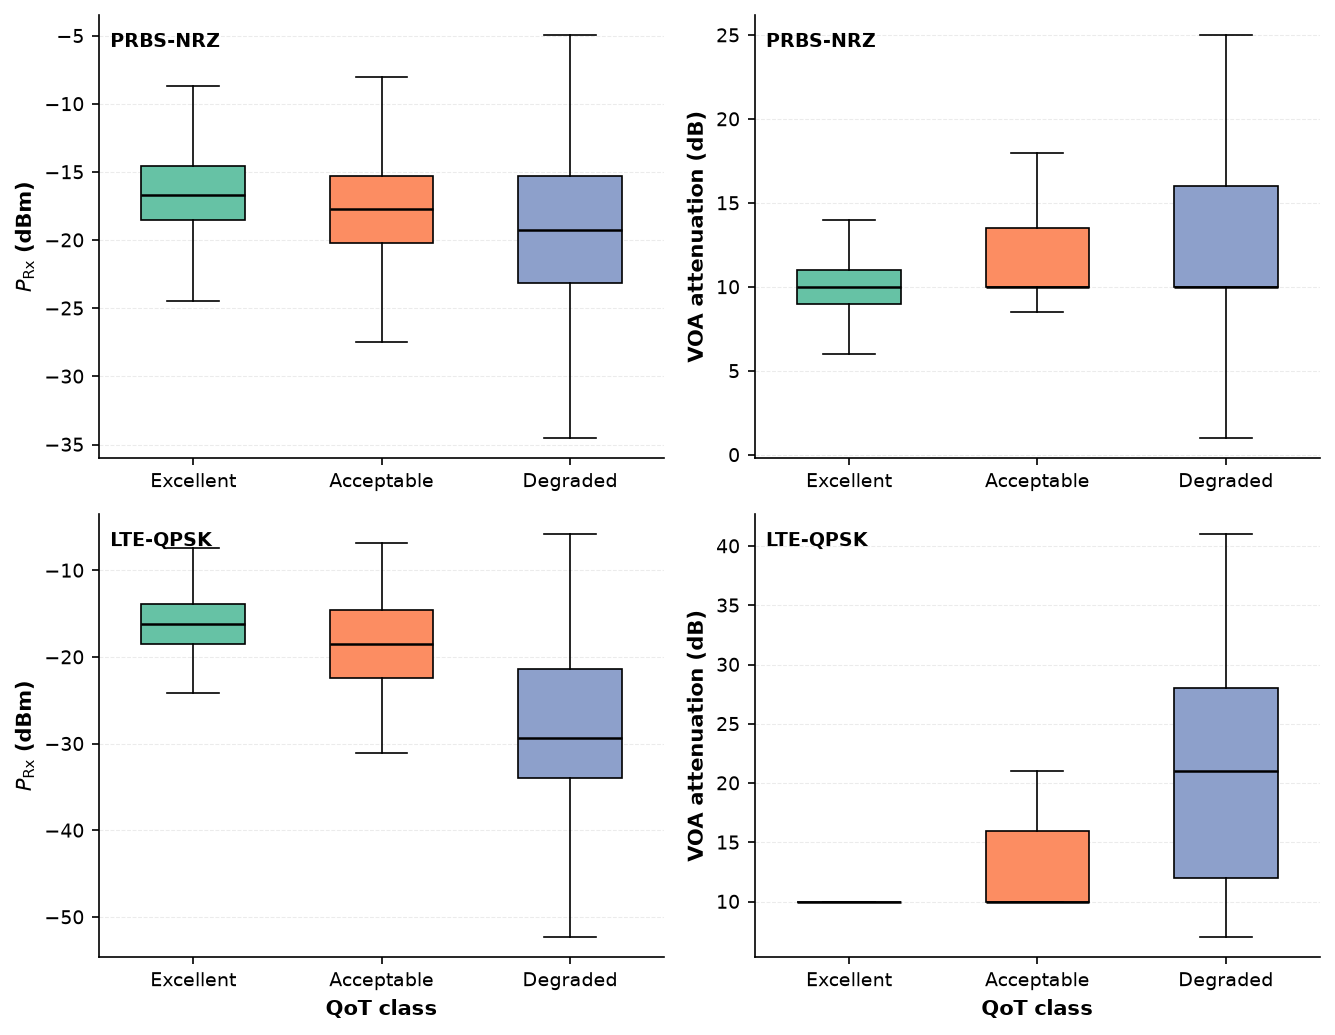

In [17]:
# Step 13 — Experimental conditions associated with QoT
# PRx and VOA attenuation by campaign and QoT class
# IEEE-style, Set2 palette

import os
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------
# Output folder
# ---------------------------------------------------------------------

output_dir = "figures/results_section"
os.makedirs(output_dir, exist_ok=True)

output_file = os.path.join(
    output_dir,
    "experimental_conditions_vs_qot.pdf"
)

# ---------------------------------------------------------------------
# Data settings
# ---------------------------------------------------------------------

campaigns = [
    ("PRBS_NRZ", "PRBS-NRZ"),
    ("LTE_QPSK", "LTE-QPSK")
]

qot_order = [
    "Excellent",
    "Acceptable",
    "Degraded"
]

variables = [
    ("prx_dbm", r"$P_{\mathrm{Rx}}$ (dBm)"),
    ("voa_attenuation_db", "VOA attenuation (dB)")
]

# Set2 palette
set2 = plt.cm.Set2.colors

class_colors = {
    "Excellent": set2[0],
    "Acceptable": set2[1],
    "Degraded": set2[2]
}

# ---------------------------------------------------------------------
# Figure
# ---------------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(9.0, 7.0),
    dpi=150
)

for row, (campaign_code, campaign_label) in enumerate(campaigns):

    campaign_df = df_qot[
        df_qot["experiment_campaign"] == campaign_code
    ]

    for col, (variable, ylabel) in enumerate(variables):

        ax = axes[row, col]

        data = [
            campaign_df[
                campaign_df["qot_class"] == qot_class
            ][variable]
            .dropna()
            .values
            for qot_class in qot_order
        ]

        bp = ax.boxplot(
            data,
            patch_artist=True,
            widths=0.55,
            showfliers=False,
            medianprops=dict(
                color="black",
                linewidth=1.2
            ),
            whiskerprops=dict(
                color="black",
                linewidth=0.8
            ),
            capprops=dict(
                color="black",
                linewidth=0.8
            ),
            boxprops=dict(
                color="black",
                linewidth=0.8
            )
        )

        # Apply Set2 colors
        for patch, qot_class in zip(
            bp["boxes"],
            qot_order
        ):
            patch.set_facecolor(
                class_colors[qot_class]
            )

        ax.set_xticks(
            [1, 2, 3]
        )

        ax.set_xticklabels(
            qot_order,
            fontsize=9
        )

        ax.set_ylabel(
            ylabel,
            fontsize=10,
            fontweight="bold"
        )

        ax.tick_params(
            axis="y",
            labelsize=9
        )

        ax.grid(
            axis="y",
            linestyle="--",
            linewidth=0.5,
            alpha=0.25
        )

        ax.set_axisbelow(True)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.spines["left"].set_linewidth(0.8)
        ax.spines["bottom"].set_linewidth(0.8)

        # Campaign label only, not a formal title
        ax.text(
            0.02,
            0.96,
            campaign_label,
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=9,
            fontweight="bold"
        )

# X labels only in bottom row
axes[1, 0].set_xlabel(
    "QoT class",
    fontsize=10,
    fontweight="bold"
)

axes[1, 1].set_xlabel(
    "QoT class",
    fontsize=10,
    fontweight="bold"
)

fig.tight_layout()

fig.savefig(
    output_file,
    format="pdf",
    bbox_inches="tight"
)

print("Saved:", output_file)

plt.show()

In [18]:
configuration_predictors = [
    "optical_tx_power_dbm",
    "wavelength_nm",
    "modulator_type",
    "modulator_attenuation_db",
    "vbias_v",
    "transmission_rate_bps",
    "rf_amplifier_tx_db",
    "rf_voltage_v",
    "rf_power_dbm",
    "smf_length_km",
    "smf_attenuation_db",
    "dispersion_ps_nm_km",
    "voa_attenuation_db",
    "edfa_current_ma",
    "soa_current_ma",
    "photodiode",
    "max_allowed_optical_power_dbm",
    "optical_receiver_responsivity_a_w",
    "detector_bw_hz",
    "rf_amplifier_rx_db"
]

In [19]:
# Step 14 — Prepare predictors for multivariate analysis

configuration_predictors = [
    "optical_tx_power_dbm",
    "wavelength_nm",
    "modulator_type",
    "modulator_attenuation_db",
    "vbias_v",
    "transmission_rate_bps",
    "rf_amplifier_tx_db",
    "rf_voltage_v",
    "rf_power_dbm",
    "smf_length_km",
    "smf_attenuation_db",
    "dispersion_ps_nm_km",
    "voa_attenuation_db",
    "edfa_current_ma",
    "soa_current_ma",
    "photodiode",
    "max_allowed_optical_power_dbm",
    "optical_receiver_responsivity_a_w",
    "detector_bw_hz",
    "rf_amplifier_rx_db"
]

categorical_predictors = [
    "modulator_type",
    "photodiode"
]

numeric_predictors = [
    col
    for col in configuration_predictors
    if col not in categorical_predictors
]

print("Configuration predictors:", len(configuration_predictors))
print("Numeric predictors:", len(numeric_predictors))
print("Categorical predictors:", len(categorical_predictors))

print("\nMissing values by predictor:")
display(
    df[configuration_predictors]
    .isna()
    .sum()
    .to_frame("Missing")
)

Configuration predictors: 20
Numeric predictors: 18
Categorical predictors: 2

Missing values by predictor:


,Missing
optical_tx_power_dbm,0
wavelength_nm,0
modulator_type,0
modulator_attenuation_db,0
vbias_v,0
transmission_rate_bps,0
rf_amplifier_tx_db,0
rf_voltage_v,0
rf_power_dbm,0
smf_length_km,0


In [20]:
# Step 15 — Campaign-specific PCA of configuration predictors
# Median imputation + one-hot encoding + standardization

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.decomposition import PCA

# ---------------------------------------------------------------------
# Preprocessing
# ---------------------------------------------------------------------

numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    )
])

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])

preprocessor = ColumnTransformer([
    (
        "numeric",
        numeric_pipeline,
        numeric_predictors
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_predictors
    )
])

# ---------------------------------------------------------------------
# Campaign-specific PCA
# ---------------------------------------------------------------------

pca_results = {}
pca_variance_rows = []

for campaign in [
    "PRBS_NRZ",
    "LTE_QPSK"
]:

    campaign_df = df[
        (
            df["experiment_campaign"] == campaign
        )
        &
        (
            df["qot_class"].isin(
                ["Excellent", "Acceptable", "Degraded"]
            )
        )
    ].copy()

    X = campaign_df[
        configuration_predictors
    ]

    # Encode + impute
    X_processed = preprocessor.fit_transform(X)

    # Remove zero-variance processed features
    feature_variance = np.var(
        X_processed,
        axis=0
    )

    nonconstant_mask = (
        feature_variance > 0
    )

    X_processed = X_processed[
        :,
        nonconstant_mask
    ]

    # Standardize all retained processed features
    scaler = StandardScaler()

    X_scaled = scaler.fit_transform(
        X_processed
    )

    # PCA
    pca = PCA(
        n_components=2
    )

    X_pca = pca.fit_transform(
        X_scaled
    )

    pca_df = pd.DataFrame({
        "PC1": X_pca[:, 0],
        "PC2": X_pca[:, 1],
        "QoT class": campaign_df[
            "qot_class"
        ].values,
        "Campaign": campaign.replace(
            "_",
            "-"
        )
    })

    pca_results[campaign] = pca_df

    pca_variance_rows.append({
        "Campaign": campaign.replace(
            "_",
            "-"
        ),
        "Observations": len(campaign_df),
        "Processed features retained":
            X_processed.shape[1],
        "PC1 explained variance (%)":
            pca.explained_variance_ratio_[0]
            * 100,
        "PC2 explained variance (%)":
            pca.explained_variance_ratio_[1]
            * 100,
        "PC1 + PC2 (%)":
            pca.explained_variance_ratio_[:2]
            .sum()
            * 100
    })


pca_variance_summary = pd.DataFrame(
    pca_variance_rows
)

display(
    pca_variance_summary.round(2)
)

,Campaign,Observations,Processed features retained,PC1 explained variance (%),PC2 explained variance (%),PC1 + PC2 (%)
0,PRBS-NRZ,4531,21,17.35,13.93,31.28
1,LTE-QPSK,1530,14,34.35,14.66,49.01


Saved: figures/results_section\pca_qot_separability_by_campaign.pdf


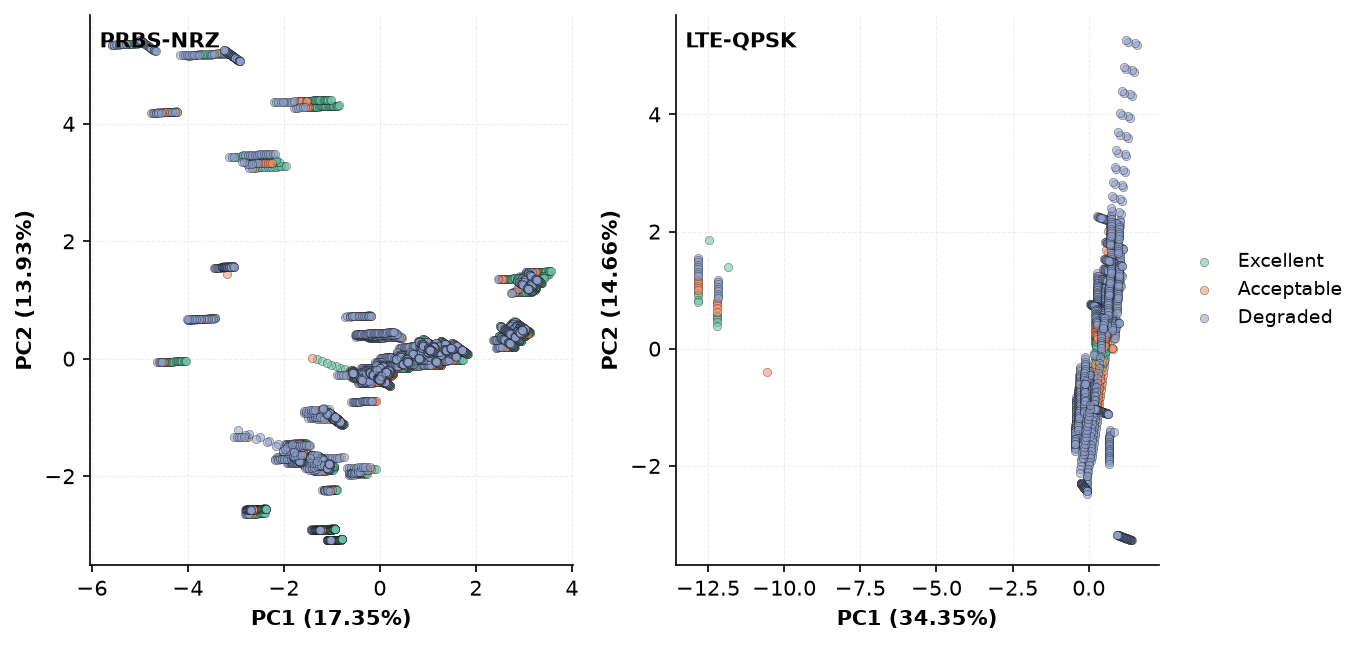

In [21]:
# Step 16 — PCA visualization by campaign
# IEEE-style, Set2 palette

import os
import matplotlib.pyplot as plt

output_dir = "figures/results_section"
os.makedirs(output_dir, exist_ok=True)

output_file = os.path.join(
    output_dir,
    "pca_qot_separability_by_campaign.pdf"
)

set2 = plt.cm.Set2.colors

class_colors = {
    "Excellent": set2[0],
    "Acceptable": set2[1],
    "Degraded": set2[2]
}

qot_order = [
    "Excellent",
    "Acceptable",
    "Degraded"
]

fig, axes = plt.subplots(
    1,
    2,
    figsize=(9.2, 4.4),
    dpi=150
)

campaign_info = [
    (
        "PRBS_NRZ",
        "PRBS-NRZ",
        17.35,
        13.93
    ),
    (
        "LTE_QPSK",
        "LTE-QPSK",
        34.35,
        14.66
    )
]

for ax, (
    campaign_code,
    campaign_label,
    pc1_var,
    pc2_var
) in zip(
    axes,
    campaign_info
):

    pca_df = pca_results[campaign_code]

    for qot_class in qot_order:

        subset = pca_df[
            pca_df["QoT class"] == qot_class
        ]

        ax.scatter(
            subset["PC1"],
            subset["PC2"],
            s=16,
            alpha=0.55,
            label=qot_class,
            color=class_colors[qot_class],
            edgecolors="black",
            linewidths=0.25
        )

    ax.set_xlabel(
        f"PC1 ({pc1_var:.2f}%)",
        fontsize=10,
        fontweight="bold"
    )

    ax.set_ylabel(
        f"PC2 ({pc2_var:.2f}%)",
        fontsize=10,
        fontweight="bold"
    )

    ax.text(
        0.02,
        0.97,
        campaign_label,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=10,
        fontweight="bold"
    )

    ax.grid(
        linestyle="--",
        linewidth=0.5,
        alpha=0.20
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)

axes[1].legend(
    frameon=False,
    fontsize=9,
    loc="center left",          # el borde izquierdo de la leyenda se ancla al punto
    bbox_to_anchor=(1.02, 0.5), # 1.0 = borde derecho del eje; mayor valor = más a la derecha
)

fig.tight_layout()

fig.savefig(
    output_file,
    format="pdf",
    bbox_inches="tight"
)

print("Saved:", output_file)

plt.show()

In [22]:
# Step 17 — Check UMAP availability

try:
    import umap
    print("UMAP available")
except ImportError:
    print("UMAP not installed")

UMAP available


In [23]:
%pip install umap-learn

Note: you may need to restart the kernel to use updated packages.


In [24]:
import umap

print("UMAP available")

UMAP available


C:\Users\jarguero\AppData\Local\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
C:\Users\jarguero\AppData\Local\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Saved: figures/results_section\umap_qot_separability_by_campaign.pdf


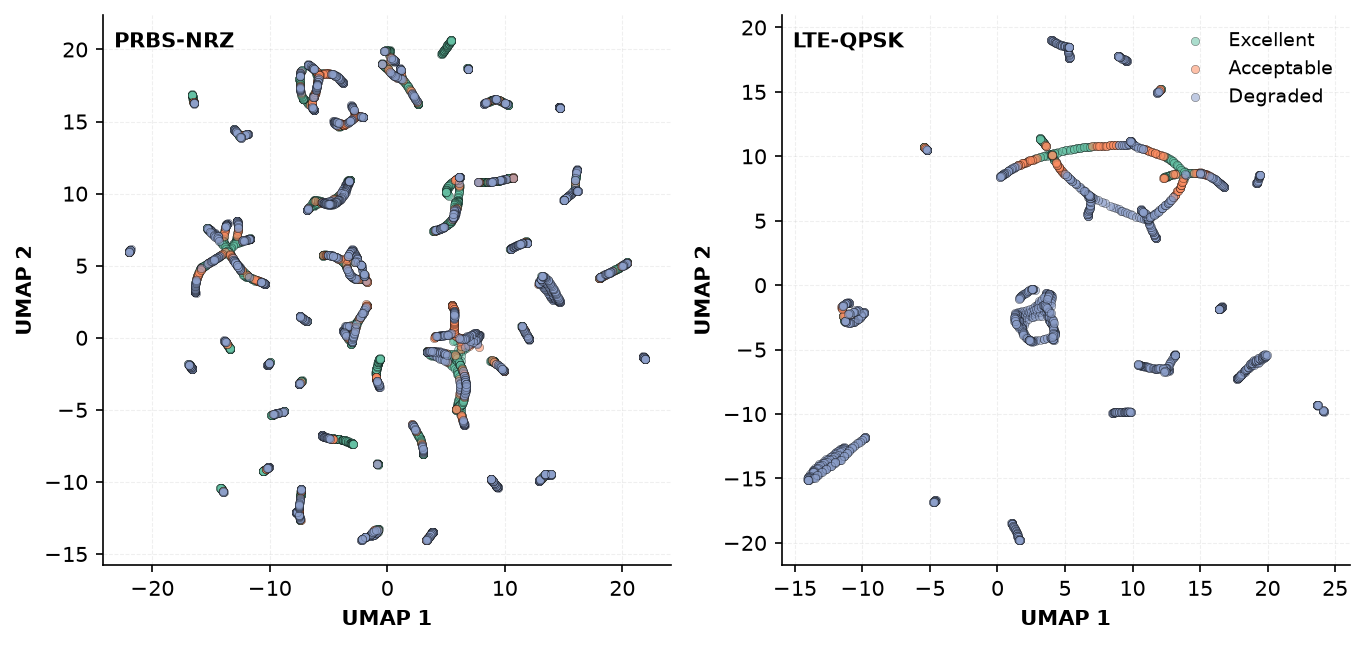

In [25]:
# Step 18 — UMAP visualization by campaign
# Configuration-based predictors
# IEEE-style, Set2 palette

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import umap

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ---------------------------------------------------------------------
# Output
# ---------------------------------------------------------------------

output_dir = "figures/results_section"
os.makedirs(output_dir, exist_ok=True)

output_file = os.path.join(
    output_dir,
    "umap_qot_separability_by_campaign.pdf"
)

# ---------------------------------------------------------------------
# Preprocessing
# ---------------------------------------------------------------------

numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    )
])

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])

preprocessor = ColumnTransformer([
    (
        "numeric",
        numeric_pipeline,
        numeric_predictors
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_predictors
    )
])

# ---------------------------------------------------------------------
# UMAP
# ---------------------------------------------------------------------

umap_results = {}

for campaign in [
    "PRBS_NRZ",
    "LTE_QPSK"
]:

    campaign_df = df[
        (
            df["experiment_campaign"] == campaign
        )
        &
        (
            df["qot_class"].isin(
                ["Excellent", "Acceptable", "Degraded"]
            )
        )
    ].copy()

    X = campaign_df[
        configuration_predictors
    ]

    # Encode + impute
    X_processed = preprocessor.fit_transform(X)

    # Remove zero-variance features
    feature_variance = np.var(
        X_processed,
        axis=0
    )

    nonconstant_mask = (
        feature_variance > 0
    )

    X_processed = X_processed[
        :,
        nonconstant_mask
    ]

    # Standardize
    scaler = StandardScaler()

    X_scaled = scaler.fit_transform(
        X_processed
    )

    # UMAP embedding
    reducer = umap.UMAP(
        n_components=2,
        n_neighbors=30,
        min_dist=0.15,
        metric="euclidean",
        random_state=42
    )

    embedding = reducer.fit_transform(
        X_scaled
    )

    umap_df = pd.DataFrame({
        "UMAP1": embedding[:, 0],
        "UMAP2": embedding[:, 1],
        "QoT class": campaign_df[
            "qot_class"
        ].values,
        "Campaign": campaign.replace(
            "_",
            "-"
        )
    })

    umap_results[campaign] = umap_df

# ---------------------------------------------------------------------
# Plot
# ---------------------------------------------------------------------

set2 = plt.cm.Set2.colors

class_colors = {
    "Excellent": set2[0],
    "Acceptable": set2[1],
    "Degraded": set2[2]
}

qot_order = [
    "Excellent",
    "Acceptable",
    "Degraded"
]

fig, axes = plt.subplots(
    1,
    2,
    figsize=(9.2, 4.4),
    dpi=150
)

campaign_info = [
    ("PRBS_NRZ", "PRBS-NRZ"),
    ("LTE_QPSK", "LTE-QPSK")
]

for ax, (
    campaign_code,
    campaign_label
) in zip(
    axes,
    campaign_info
):

    umap_df = umap_results[
        campaign_code
    ]

    for qot_class in qot_order:

        subset = umap_df[
            umap_df["QoT class"] == qot_class
        ]

        ax.scatter(
            subset["UMAP1"],
            subset["UMAP2"],
            s=16,
            alpha=0.55,
            label=qot_class,
            color=class_colors[qot_class],
            edgecolors="black",
            linewidths=0.25
        )

    ax.set_xlabel(
        "UMAP 1",
        fontsize=10,
        fontweight="bold"
    )

    ax.set_ylabel(
        "UMAP 2",
        fontsize=10,
        fontweight="bold"
    )

    ax.text(
        0.02,
        0.97,
        campaign_label,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=10,
        fontweight="bold"
    )

    ax.grid(
        linestyle="--",
        linewidth=0.5,
        alpha=0.20
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)

axes[1].legend(
    frameon=False,
    fontsize=9,
    loc="best"
)

fig.tight_layout()

fig.savefig(
    output_file,
    format="pdf",
    bbox_inches="tight"
)

print("Saved:", output_file)

plt.show()

In [26]:
# Step 19 — Load final machine-learning benchmark table

import pandas as pd
from pathlib import Path

benchmark_path = Path(
    "tables/table_main_benchmark_manuscript.csv"
)

benchmark_main = pd.read_csv(
    benchmark_path
)

print(
    "Shape:",
    benchmark_main.shape
)

display(
    benchmark_main
)

Shape: (16, 8)


,Campaign,Scenario,Model,Accuracy,Macro-F1,Balanced Accuracy,MCC,ROC-AUC Macro OvR
0,LTE-QPSK,Configuration,SVM,0.981,0.910,0.877,0.898,0.931
1,LTE-QPSK,Configuration,MLP,0.978,0.906,0.914,0.887,0.981
2,LTE-QPSK,Configuration,GB,0.972,0.866,0.874,0.854,0.984
3,LTE-QPSK,Configuration,RF,0.965,0.808,0.813,0.820,0.981
4,LTE-QPSK,Telemetry,SVM,0.978,0.897,0.875,0.881,0.915
5,LTE-QPSK,Telemetry,MLP,0.975,0.889,0.896,0.871,0.986
6,LTE-QPSK,Telemetry,GB,0.978,0.884,0.876,0.883,0.975
7,LTE-QPSK,Telemetry,RF,0.972,0.844,0.852,0.853,0.977
8,PRBS-NRZ,Configuration,GB,0.840,0.777,0.771,0.740,0.927
9,PRBS-NRZ,Configuration,MLP,0.845,0.777,0.767,0.746,0.942


,Campaign,Scenario,All correct,Misclassified by >=3 models,Misclassified by all 4 models
0,PRBS-NRZ,Configuration,19.858,45.390,33.333
1,PRBS-NRZ,Telemetry,16.312,46.809,34.043
2,LTE-QPSK,Configuration,43.750,12.500,6.250
3,LTE-QPSK,Telemetry,43.750,12.500,6.250


Saved: figures/results_section\acceptable_classification_difficulty.pdf


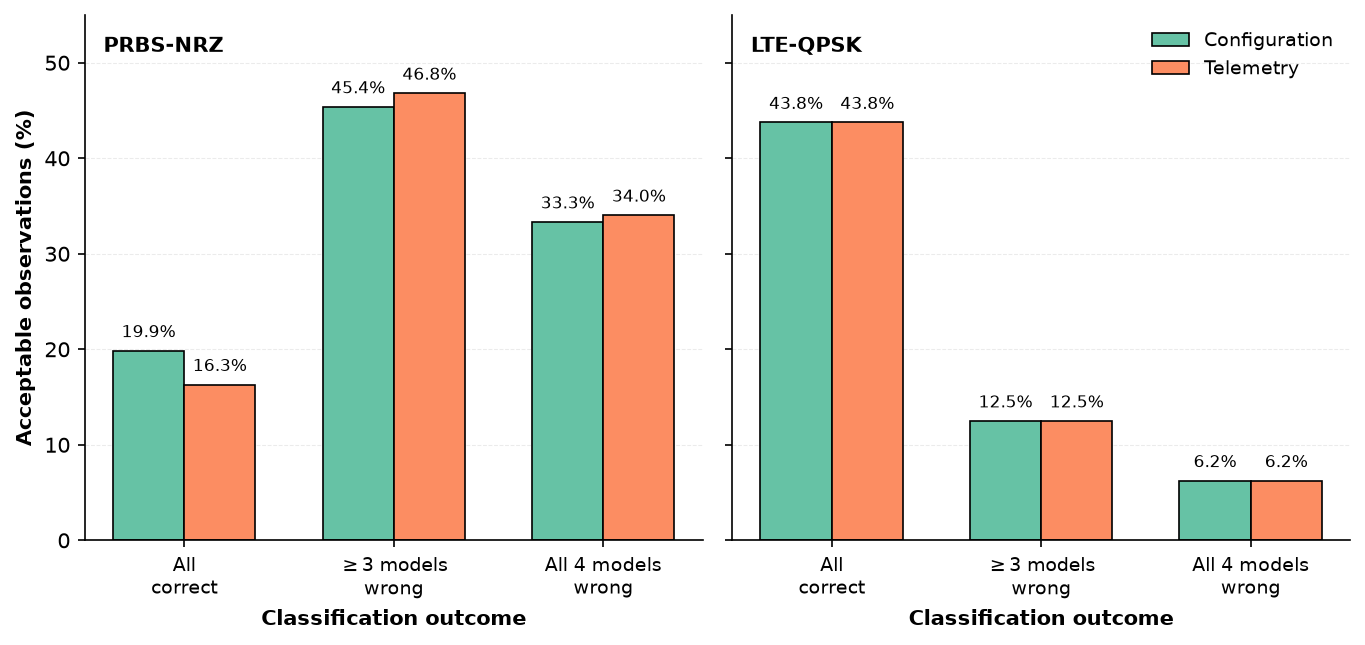

In [27]:
# Step 21 — Classification difficulty of the Acceptable QoT class
# Consensus errors across the four evaluated models

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------
# Results from Activity 16
# ---------------------------------------------------------------------

failure_summary = pd.DataFrame({
    "Campaign": [
        "PRBS-NRZ", "PRBS-NRZ",
        "LTE-QPSK", "LTE-QPSK"
    ],
    "Scenario": [
        "Configuration", "Telemetry",
        "Configuration", "Telemetry"
    ],
    "All correct": [
        19.858,
        16.312,
        43.750,
        43.750
    ],
    "Misclassified by >=3 models": [
        45.390,
        46.809,
        12.500,
        12.500
    ],
    "Misclassified by all 4 models": [
        33.333,
        34.043,
        6.250,
        6.250
    ]
})

display(failure_summary)

# ---------------------------------------------------------------------
# Output
# ---------------------------------------------------------------------

output_dir = "figures/results_section"
os.makedirs(output_dir, exist_ok=True)

output_file = os.path.join(
    output_dir,
    "acceptable_classification_difficulty.pdf"
)

# ---------------------------------------------------------------------
# Plot
# ---------------------------------------------------------------------

set2 = plt.cm.Set2.colors

metrics = [
    "All correct",
    "Misclassified by >=3 models",
    "Misclassified by all 4 models"
]

scenario_colors = {
    "Configuration": set2[0],
    "Telemetry": set2[1]
}

fig, axes = plt.subplots(
    1,
    2,
    figsize=(9.2, 4.4),
    sharey=True,
    dpi=150
)

campaigns = [
    "PRBS-NRZ",
    "LTE-QPSK"
]

x = np.arange(len(metrics))
width = 0.34

for ax, campaign in zip(axes, campaigns):

    subset = failure_summary[
        failure_summary["Campaign"] == campaign
    ]

    for offset, scenario in zip(
        [-width / 2, width / 2],
        ["Configuration", "Telemetry"]
    ):

        row = subset[
            subset["Scenario"] == scenario
        ].iloc[0]

        values = [
            row[metric]
            for metric in metrics
        ]

        bars = ax.bar(
            x + offset,
            values,
            width,
            label=scenario,
            color=scenario_colors[scenario],
            edgecolor="black",
            linewidth=0.8
        )

        for bar, value in zip(bars, values):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 1.0,
                f"{value:.1f}%",
                ha="center",
                va="bottom",
                fontsize=8
            )

    ax.set_xticks(x)

    ax.set_xticklabels(
        [
            "All\ncorrect",
            r"$\geq$3 models" + "\nwrong",
            "All 4 models\nwrong"
        ],
        fontsize=9
    )

    ax.set_xlabel(
        "Classification outcome",
        fontweight="bold"
    )

    ax.text(
        0.03,
        0.96,
        campaign,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontweight="bold"
    )

    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.5,
        alpha=0.25
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)

axes[0].set_ylabel(
    "Acceptable observations (%)",
    fontweight="bold"
)

axes[1].legend(
    frameon=False,
    fontsize=9,
    loc="upper right"
)

axes[0].set_ylim(0, 55)

fig.tight_layout()

fig.savefig(
    output_file,
    format="pdf",
    bbox_inches="tight"
)

print("Saved:", output_file)

plt.show()

In [28]:
import pandas as pd

failure_table = pd.read_csv(
    "tables/table_failure_region_manuscript.csv"
)

print(failure_table.shape)
display(failure_table)

(12, 8)


,Campaign,Scenario,Feature label,Easy median,Hard median,Hard - Easy,Robust median shift,Absolute robust shift
0,LTE_QPSK,Configuration-based,Vbias,3.100000e+00,6.000000e-01,-2.500000e+00,-0.757576,0.757576
1,LTE_QPSK,Configuration-based,SOA current,2.150000e+02,1.891000e+02,-2.590000e+01,-0.448485,0.448485
2,LTE_QPSK,Configuration-based,VOA attenuation,1.900000e+01,2.100000e+01,2.000000e+00,0.333333,0.333333
3,LTE_QPSK,Telemetry-assisted,Vbias,3.100000e+00,6.000000e-01,-2.500000e+00,-0.757576,0.757576
4,LTE_QPSK,Telemetry-assisted,PRx,-2.383000e+01,-2.678000e+01,-2.950000e+00,-0.514161,0.514161
5,LTE_QPSK,Telemetry-assisted,SOA current,2.150000e+02,1.891000e+02,-2.590000e+01,-0.448485,0.448485
6,PRBS_NRZ,Configuration-based,Vbias,4.400000e+00,2.400000e+00,-2.000000e+00,-0.952381,0.952381
7,PRBS_NRZ,Configuration-based,VOA attenuation,1.100000e+01,1.000000e+01,-1.000000e+00,-0.400000,0.400000
8,PRBS_NRZ,Configuration-based,SOA current,1.961000e+02,1.975000e+02,1.400000e+00,0.170732,0.170732
9,PRBS_NRZ,Telemetry-assisted,VOA attenuation,1.250000e+01,1.000000e+01,-2.500000e+00,-1.000000,1.000000


Saved: figures/results_section\pca_qot_separability_by_campaign.pdf


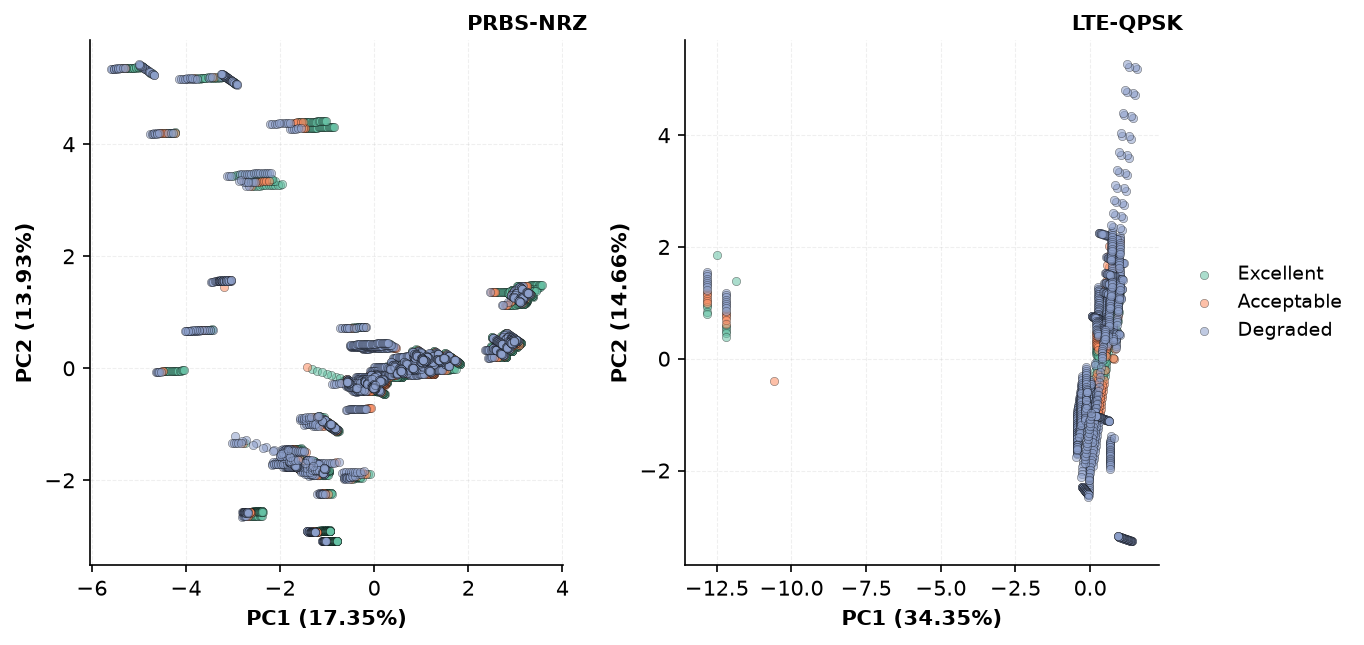

In [42]:
# Step 16 — PCA visualization by campaign
# IEEE-style, Set2 palette

import os
import matplotlib.pyplot as plt

output_dir = "figures/results_section"
os.makedirs(output_dir, exist_ok=True)

output_file = os.path.join(
    output_dir,
    "pca_qot_separability_by_campaign.pdf"
)

set2 = plt.cm.Set2.colors

class_colors = {
    "Excellent": set2[0],
    "Acceptable": set2[1],
    "Degraded": set2[2]
}

qot_order = [
    "Excellent",
    "Acceptable",
    "Degraded"
]

fig, axes = plt.subplots(
    1,
    2,
    figsize=(9.2, 4.4),
    dpi=150
)

campaign_info = [
    (
        "PRBS_NRZ",
        "PRBS-NRZ",
        17.35,
        13.93
    ),
    (
        "LTE_QPSK",
        "LTE-QPSK",
        34.35,
        14.66
    )
]

for ax, (
    campaign_code,
    campaign_label,
    pc1_var,
    pc2_var
) in zip(
    axes,
    campaign_info
):

    pca_df = pca_results[campaign_code]

    for qot_class in qot_order:

        subset = pca_df[
            pca_df["QoT class"] == qot_class
        ]

        ax.scatter(
            subset["PC1"],
            subset["PC2"],
            s=16,
            alpha=0.55,
            label=qot_class,
            color=class_colors[qot_class],
            edgecolors="black",
            linewidths=0.25
        )

    ax.set_xlabel(
        f"PC1 ({pc1_var:.2f}%)",
        fontsize=10,
        fontweight="bold"
    )

    ax.set_ylabel(
        f"PC2 ({pc2_var:.2f}%)",
        fontsize=10,
        fontweight="bold"
    )

    ax.text(
        1.05,
        1.05,
        campaign_label,
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=10,
        fontweight="bold"
    )
    ax.grid(
        linestyle="--",
        linewidth=0.5,
        alpha=0.20
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)

axes[1].legend(
    frameon=False,
    fontsize=9,
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),  # Mayor valor (ej. 1.05, 1.1) = más separada a la derecha
)

fig.tight_layout()

fig.savefig(
    output_file,
    format="pdf",
    bbox_inches="tight"
)

print("Saved:", output_file)

plt.show()

In [ ]:
import sys
import platform
import importlib.metadata as metadata
from pathlib import Path
from datetime import datetime, timezone

# Bibliotecas relevantes para el benchmark QoT
packages = [
    "numpy",
    "pandas",
    "scipy",
    "scikit-learn",
    "matplotlib",
    "seaborn",
    "openpyxl",
    "joblib",
    "jupyterlab",
    "notebook",
    "ipykernel"
]

# Información del entorno de ejecución
environment = {
    "Python": platform.python_version(),
    "Python executable": sys.executable,
    "Operating system": platform.platform()
}

# Obtener las versiones instaladas
for package in packages:
    try:
        environment[package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        environment[package] = "Not installed"

# Mostrar resultados
print("=" * 55)
print("SOFTWARE ENVIRONMENT - QoT ML BENCHMARK")
print("=" * 55)

for name, version in environment.items():
    print(f"{name:<22}: {version}")

# Guardar los resultados en un archivo de texto
output_dir = Path("results")
output_dir.mkdir(exist_ok=True)

output_file = output_dir / "software_environment.txt"

with open(output_file, "w", encoding="utf-8") as f:
    f.write("SOFTWARE ENVIRONMENT - QoT ML BENCHMARK\n")
    f.write(f"Recorded at (UTC): {datetime.now(timezone.utc).isoformat()}\n\n")

    for name, version in environment.items():
        f.write(f"{name}: {version}\n")

print("\nEnvironment information saved to:")
print(output_file.resolve())